**Célula 1 – setup:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import set_seed, SEED, DIMS, get_splits
from src.representation import fit_pca, pca_project, pca_reconstruct

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()

**Célula 2 – ajustar o PCA (só treino):**

In [2]:
start = time.perf_counter()
pca = fit_pca(X_train)
print(f"PCA ajustado em {time.perf_counter() - start:.1f} s | n.º componentes: {pca.n_components_}")

evr = pca.explained_variance_ratio_    
cum_evr = np.cumsum(evr)                

print("Variância das 10 primeiras componentes:", np.round(evr[:10], 3))

PCA ajustado em 10.3 s | n.º componentes: 784
Variância das 10 primeiras componentes: [0.29  0.178 0.06  0.049 0.039 0.035 0.023 0.019 0.014 0.013]


**Célula 3 – quantas componentes para 80/90/95/99%:**

In [3]:
rows = []
for thr in [0.80, 0.90, 0.95, 0.99]:
    k = int(np.searchsorted(cum_evr, thr) + 1)   
    rows.append({"variance_threshold": thr, "n_components": k})
thr_table = pd.DataFrame(rows)
print(thr_table.to_string(index=False))

# variância acumulada nas dimensões do enunciado
dims_table = pd.DataFrame({"dim": DIMS, "cumulative_variance": [cum_evr[d - 1] for d in DIMS]})
print(dims_table.round(3).to_string(index=False))

thr_table.to_csv("results/tables/04_pca_thresholds.csv", index=False)
dims_table.to_csv("results/tables/04_pca_variance_by_dim.csv", index=False)

 variance_threshold  n_components
               0.80            24
               0.90            84
               0.95           187
               0.99           459
 dim  cumulative_variance
   2                0.468
   8                0.693
  16                0.765
  32                0.826
  64                0.881
 128                0.928


**Célula 4 – gráfico da variância acumulada:**

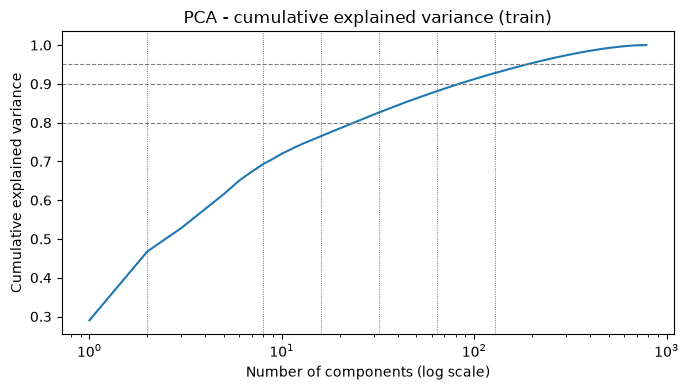

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(cum_evr) + 1), cum_evr)                
for thr in [0.80, 0.90, 0.95]:
    ax.axhline(thr, ls="--", lw=0.8, color="gray")               
for d in DIMS:
    ax.axvline(d, ls=":", lw=0.6, color="red")                   
ax.set_xscale("log")                                            
ax.set_xlabel("Number of components (log scale)")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("PCA - cumulative explained variance (train)")
plt.tight_layout()
plt.savefig("results/figures/04_pca_cumulative_variance.png", dpi=150, bbox_inches="tight")
plt.show()

**Célula 5 – erro de reconstrução na validação:**

 dim  val_mse
   2  0.04617
   8  0.02660
  16  0.02038
  32  0.01510
  64  0.01031
 128  0.00627


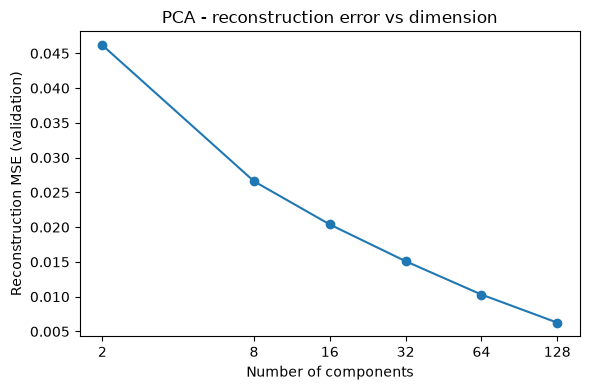

In [5]:
rec_rows = []
for d in DIMS:
    Z_val = pca_project(pca, X_val, d)           
    X_val_rec = pca_reconstruct(pca, Z_val)       
    mse = np.mean((X_val - X_val_rec) ** 2)      
    rec_rows.append({"dim": d, "val_mse": mse})
rec_table = pd.DataFrame(rec_rows)
print(rec_table.round(5).to_string(index=False))
rec_table.to_csv("results/tables/04_pca_reconstruction_mse.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rec_table["dim"], rec_table["val_mse"], marker="o")
ax.set_xscale("log", base=2)                      
ax.set_xticks(DIMS, labels=DIMS)
ax.set_xlabel("Number of components")
ax.set_ylabel("Reconstruction MSE (validation)")
ax.set_title("PCA - reconstruction error vs dimension")
plt.tight_layout()
plt.savefig("results/figures/04_pca_reconstruction_mse.png", dpi=150, bbox_inches="tight")
plt.show()

**Célula 6 – ver a imagem média e as primeiras componentes:**

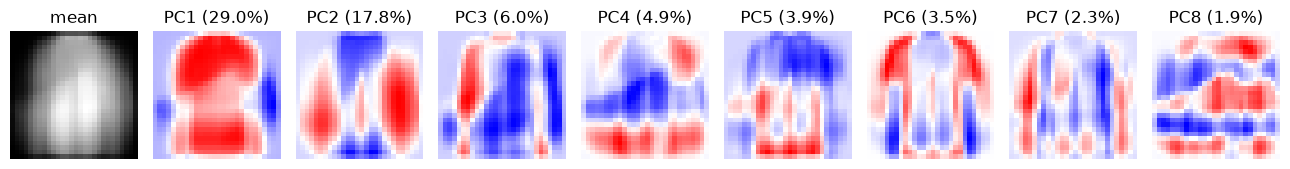

In [ ]:
fig, axes = plt.subplots(1, 9, figsize=(13, 2))
axes[0].imshow(pca.mean_.reshape(28, 28), cmap="gray")
axes[0].set_title("mean")
for i in range(8):
    axes[i + 1].imshow(pca.components_[i].reshape(28, 28), cmap="bwr") 
    axes[i + 1].set_title(f"PC{i + 1} ({evr[i]:.1%})")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("results/figures/04_pca_mean_and_components.png", dpi=150, bbox_inches="tight")
plt.show()